# JS09: Lab 5

Uji recall dan waktu query Annoy, FAISS IVF, serta HNSW. Dataset berisi 100.000 vektor berdimensi 128 dan 1.000 query. Setiap parameter membangun indeks baru sesuai kode panduan, sehingga bagian ini membutuhkan waktu lebih lama.

## Instalasi library

In [1]:
%pip install -q annoy==1.17.3 faiss-cpu==1.13.2 hnswlib==0.8.0

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\syahr\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


## Import library

In [2]:
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt

## Membuat dataset

In [3]:
d = 128
nb = 100000
nq = 1000

np.random.seed(42)
xb = np.random.random((nb, d)).astype('float32')
xq = np.random.random((nq, d)).astype('float32')

## Ground truth dengan FAISS brute force

In [4]:
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
k = 10
_, gt_idx = index_flat.search(xq, k)

## Recall query

In [5]:
def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

## Benchmark Annoy

In [6]:
def run_annoy(xb, xq, n_trees=10, search_k=1000, k=10):
    f = xb.shape[1]
    index = AnnoyIndex(f, 'euclidean')
    for i, v in enumerate(xb):
        index.add_item(i, v)
    index.build(n_trees)

    start = time.time()
    I = [index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

## Benchmark FAISS IVF

In [7]:
def run_faiss(xb, xq, nlist=100, nprobe=10, k=10):
    quantizer = faiss.IndexFlatL2(d)
    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
    index.train(xb)
    index.add(xb)

    index.nprobe = nprobe
    start = time.time()
    _, I = index.search(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

## Benchmark HNSW

In [8]:
def run_hnsw(xb, xq, ef=100, M=16, k=10):
    num_elements = xb.shape[0]
    p = hnswlib.Index(space='l2', dim=d)
    p.init_index(max_elements=num_elements, ef_construction=200, M=M)
    p.add_items(xb)
    p.set_ef(ef)

    start = time.time()
    I, _ = p.knn_query(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

## Menyiapkan hasil

In [9]:
results = {"Annoy": [], "Faiss": [], "HNSW": []}

## Percobaan search_k Annoy

In [10]:
for sk in [200, 500, 1000, 2000]:
    rec, t = run_annoy(xb, xq, n_trees=10, search_k=sk)
    results["Annoy"].append((rec, t))

## Percobaan nprobe FAISS

In [11]:
for npb in [1, 5, 10, 20]:
    rec, t = run_faiss(xb, xq, nlist=100, nprobe=npb)
    results["Faiss"].append((rec, t))

## Percobaan ef HNSW

In [12]:
for ef in [50, 100, 200, 400]:
    rec, t = run_hnsw(xb, xq, ef=ef)
    results["HNSW"].append((rec, t))

## Tabel hasil

In [13]:
import pandas as pd

parameter_values = {
    'Annoy': ('search_k', [200, 500, 1000, 2000]),
    'Faiss': ('nprobe', [1, 5, 10, 20]),
    'HNSW': ('ef', [50, 100, 200, 400]),
}
rows = []
for algorithm, values in results.items():
    parameter, settings = parameter_values[algorithm]
    for setting, (rec, elapsed) in zip(settings, values):
        rows.append({'Algoritma': algorithm, 'Parameter': f'{parameter}={setting}',
                     'Recall@10': rec, 'Waktu (ms/query)': elapsed})
benchmark_table = pd.DataFrame(rows)
print(benchmark_table.to_string(index=False, float_format=lambda value: f'{value:.6f}'))

Algoritma     Parameter  Recall@10  Waktu (ms/query)
    Annoy  search_k=200   0.027600          0.088545
    Annoy  search_k=500   0.051000          0.177981
    Annoy search_k=1000   0.085600          0.370627
    Annoy search_k=2000   0.138100          0.544197
    Faiss      nprobe=1   0.055800          0.020507
    Faiss      nprobe=5   0.198100          0.092349
    Faiss     nprobe=10   0.324000          0.214598
    Faiss     nprobe=20   0.503100          0.399356
     HNSW         ef=50   0.296300          0.091789
     HNSW        ef=100   0.434800          0.173497
     HNSW        ef=200   0.609200          0.303074
     HNSW        ef=400   0.769300          0.543309


## Visualisasi

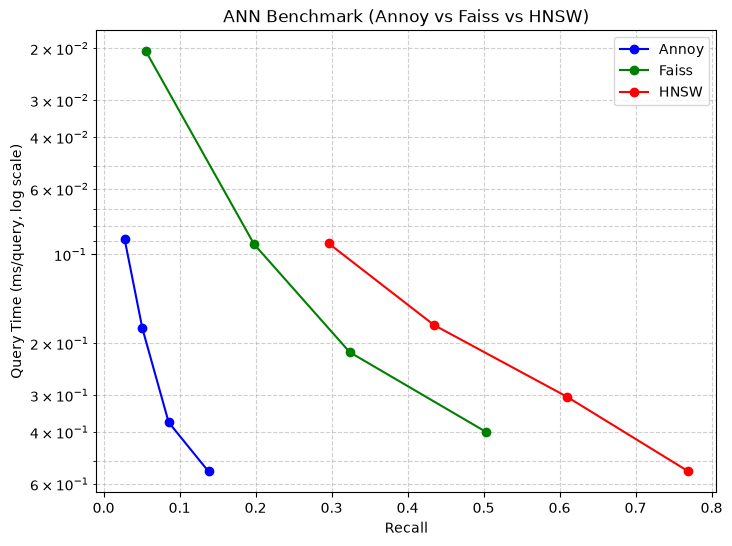

In [14]:
plt.figure(figsize=(8,6))
for label, color in zip(results.keys(), ["blue","green","red"]):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker="o", label=label, color=color)

plt.xlabel("Recall")
plt.ylabel("Query Time (ms/query, log scale)")
plt.yscale("log")
plt.gca().invert_yaxis()
plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()

Recall@10 menunjukkan proporsi tetangga yang sama dengan hasil exact. Grafik memakai waktu per query dengan sumbu Y terbalik, seperti kode panduan. Posisi lebih ke kanan berarti recall lebih tinggi, sedangkan posisi lebih ke atas berarti pencarian lebih cepat. Nilai waktu dan recall ANN dapat berbeda antar eksekusi.